# 9. Image Matching

## Table of Contents
1. [Libraries](#libraries)
1. [ORB Matching](#orb)
1. [SIFT Matching](#sift)

## Equipo 11
## Alumnos
#### Hector Gerardo Paredes Castillo A01796892
#### Andres Marcelo Fernandez Loredo A01281054
#### Jose Angel Barajas Flores A01797221
#### Gilberto Valencia Acosta A01273602


## Importing Libraries <a class="anchor" id="libraries" ></a>

In [2]:
import cv2 
import matplotlib.pyplot as plt
import numpy as np

# ORB (Oriented FAST and Rotated BRIEF) <a class="anchor" id="orb" ></a>

- Developed at OpenCV labs by Ethan Rublee, Vincent Rabaud, Kurt Konolige, and Gary R. Bradski in 2011
- Efficient and viable alternative to SIFT and SURF (patented algorithms)
- ORB is free to use
- Feature detection
- ORB builds on FAST keypoint detector + BRIEF descriptor

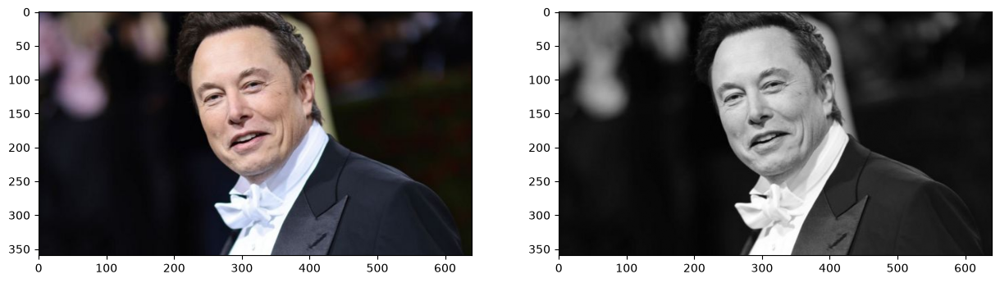

In [3]:
#reading image
img = cv2.imread('/home/barajas_angel/repos/TC4033.10_vision_computacional/data/elon_1.jpg')  
img_color = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
img_gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

plt.figure(figsize=(15, 8))
plt.subplot(1, 2, 1)
plt.imshow(img_color)
plt.subplot(1, 2, 2)
plt.imshow(img_gray, cmap="gray")

### Create test image by adding Scale Invariance and Rotational Invariance

In [4]:
test_image = cv2.pyrDown(img_color)
test_image = cv2.pyrDown(test_image)
num_rows, num_cols = test_image.shape[:2]

rotation_matrix = cv2.getRotationMatrix2D((num_cols/2, num_rows/2), 30, 1)
test_image = cv2.warpAffine(test_image, rotation_matrix, (num_cols, num_rows))

test_gray = cv2.cvtColor(test_image, cv2.COLOR_RGB2GRAY)

### Display traning image and testing image

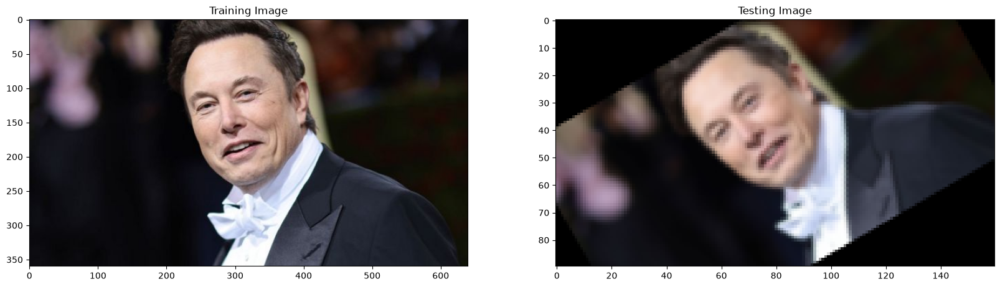

In [5]:
fx, plots = plt.subplots(1, 2, figsize=(20,10))

plots[0].set_title("Training Image")
plots[0].imshow(img_color)

plots[1].set_title("Testing Image")
plots[1].imshow(test_image)

### ORB

In [6]:
orb = cv2.ORB_create()

Number of Keypoints Detected In The Training Image:  500
Number of Keypoints Detected In The Query Image:  42


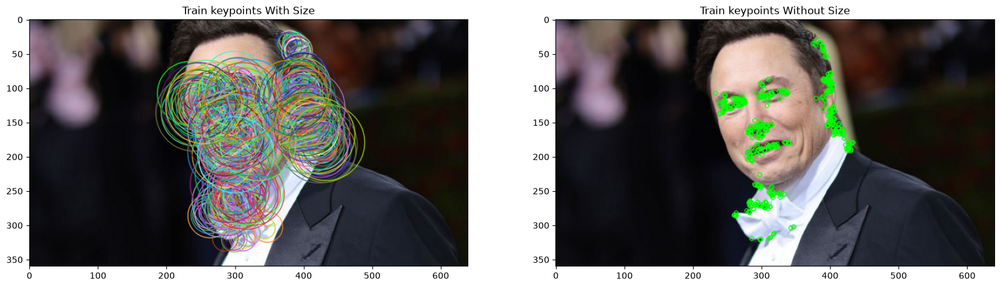

In [7]:
train_keypoints, train_descriptor = orb.detectAndCompute(img_color, None)
test_keypoints, test_descriptor = orb.detectAndCompute(test_gray, None)

keypoints_without_size = np.copy(img_color)
keypoints_with_size = np.copy(img_color)

cv2.drawKeypoints(img_color, train_keypoints, keypoints_without_size, color = (0, 255, 0))

cv2.drawKeypoints(img_color, train_keypoints, keypoints_with_size, flags = cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)

# Display image with and without keypoints size
fx, plots = plt.subplots(1, 2, figsize=(20,10))

plots[0].set_title("Train keypoints With Size")
plots[0].imshow(keypoints_with_size, cmap='gray')

plots[1].set_title("Train keypoints Without Size")
plots[1].imshow(keypoints_without_size, cmap='gray')

# Print the number of keypoints detected in the training image
print("Number of Keypoints Detected In The Training Image: ", len(train_keypoints))

# Print the number of keypoints detected in the query image
print("Number of Keypoints Detected In The Query Image: ", len(test_keypoints))

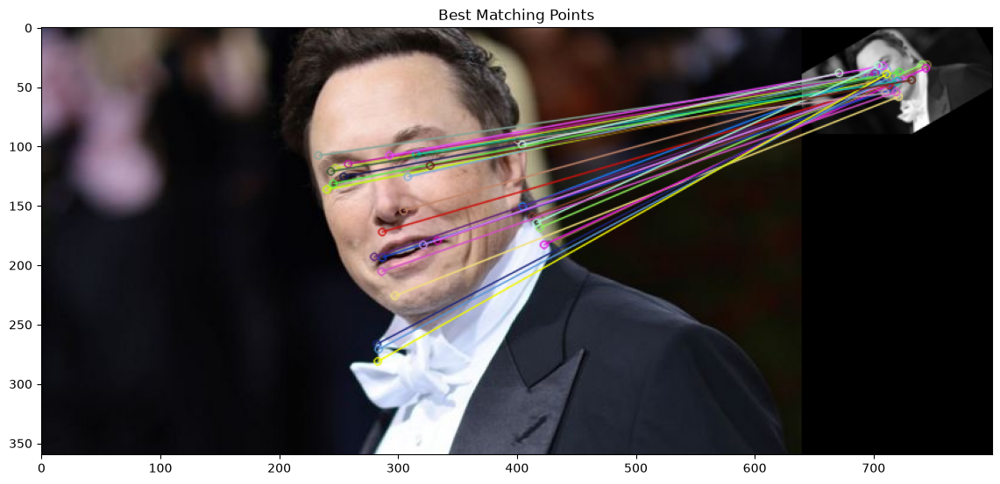


Number of Matching Keypoints Between The Training and Query Images:  30


In [8]:

# Create a Brute Force Matcher object.
bf = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck = True)

# Perform the matching between the ORB descriptors of the training image and the test image
matches = bf.match(train_descriptor, test_descriptor)

# The matches with shorter distance are the ones we want.
matches = sorted(matches, key = lambda x : x.distance)

result = cv2.drawMatches(img_color, train_keypoints, test_gray, test_keypoints, matches, test_gray, flags = 2)

# Display the best matching points
plt.rcParams['figure.figsize'] = [14.0, 7.0]
plt.title('Best Matching Points')
plt.imshow(result)
plt.show()

# Print total number of matching points between the training and query images
print("\nNumber of Matching Keypoints Between The Training and Query Images: ", len(matches))

## SIFT Matching (Scale Invariant Feature Transform) <a class="anchor" id="sift" ></a>

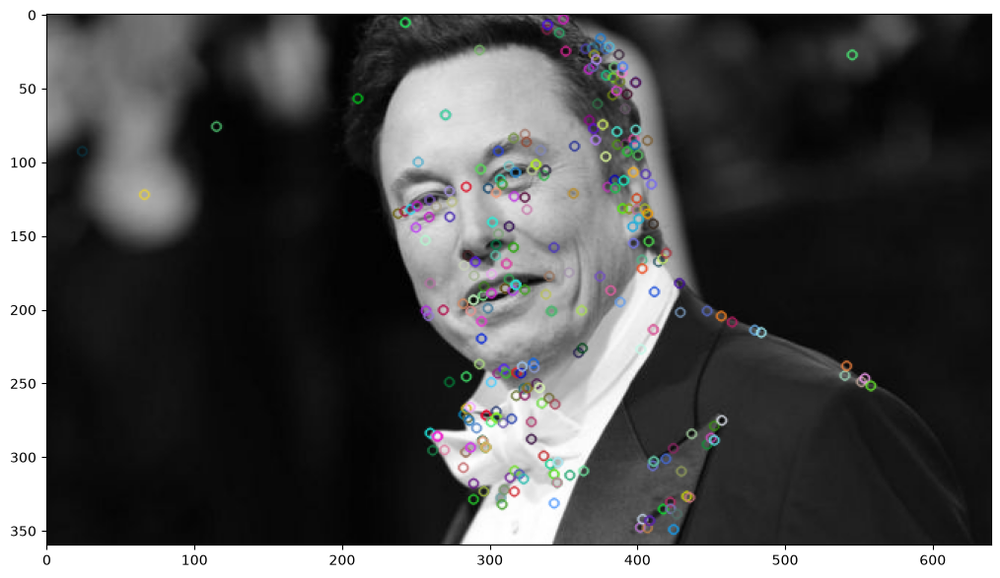

In [9]:
img1 = cv2.imread('/home/barajas_angel/repos/TC4033.10_vision_computacional/data/elon_1.jpg')  
gray1 = cv2.cvtColor(img1, cv2.COLOR_BGR2GRAY)

#keypoints
sift = cv2.SIFT_create()
keypoints_1, descriptors_1 = sift.detectAndCompute(img1,None)

img_1 = cv2.drawKeypoints(gray1,keypoints_1,img1)
plt.imshow(img_1)

### Matching different images

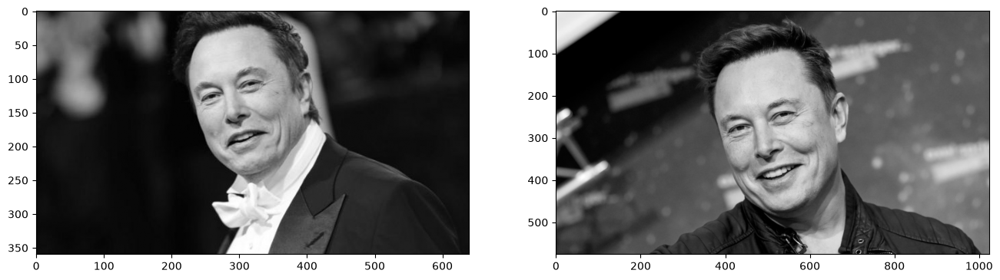

In [10]:
# read images
img1 = cv2.imread('/home/barajas_angel/repos/TC4033.10_vision_computacional/data/elon_1.jpg')  
img2 = cv2.imread('/home/barajas_angel/repos/TC4033.10_vision_computacional/data/elon_2.png') 

img1 = cv2.cvtColor(img1, cv2.COLOR_BGR2GRAY)
img2 = cv2.cvtColor(img2, cv2.COLOR_BGR2GRAY)

figure, ax = plt.subplots(1, 2, figsize=(16, 8))

ax[0].imshow(img1, cmap='gray')
ax[1].imshow(img2, cmap='gray')

### Extracting Keypoints with SIFT

In [11]:
#sift
sift = cv2.SIFT_create()

keypoints_1, descriptors_1 = sift.detectAndCompute(img1,None)
keypoints_2, descriptors_2 = sift.detectAndCompute(img2,None)

len(keypoints_1), len(keypoints_2)

(291, 734)

### Feature Matching

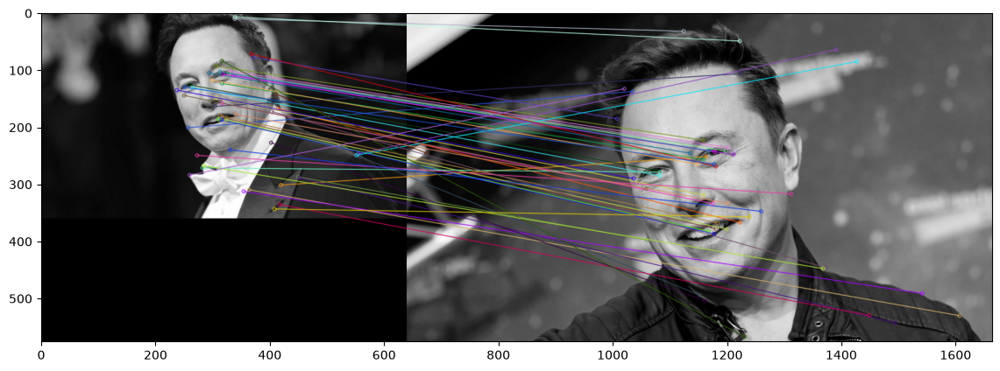

(<matplotlib.image.AxesImage at 0x7fa62e634050>, None)

In [12]:
#feature matching
bf = cv2.BFMatcher(cv2.NORM_L1, crossCheck=True)

matches = bf.match(descriptors_1,descriptors_2)
matches = sorted(matches, key = lambda x:x.distance)

img3 = cv2.drawMatches(img1, keypoints_1, img2, keypoints_2, matches[:50], img2, flags=2)
plt.imshow(img3),plt.show()

### Start working from here

## Experimento — Matching ORB vs SIFT sobre el dron BSKLab

**Justificación (dominio BSKLab):** se utiliza una fotografía real del dron eFoiler (quadplane) de
la flota BSKLab (`drone_1.jpg`, frontal) como imagen base. Se generan dos variantes sintéticas:
(i) iluminación reducida (a=0.6, b=−15) y (ii) rotación de 30°. Además, se incluye un caso real de
matching entre dos ángulos distintos (drone_1 frontal vs drone_2 vista 3/4) para evaluar el
comportamiento ante cambio de perspectiva.

**Enfoque:** se **replica exactamente** el código del notebook de clase (ORB: `cv2.ORB_create()` +
`BFMatcher(NORM_HAMMING, crossCheck=True)`; SIFT: `cv2.SIFT_create()` + `BFMatcher(NORM_L1)` + ratio
test 0.75). No se modifica ninguna línea del template. Se comparan ORB (rápido, binario) vs SIFT
(128-d, flotante, más robusto) bajo las tres condiciones.


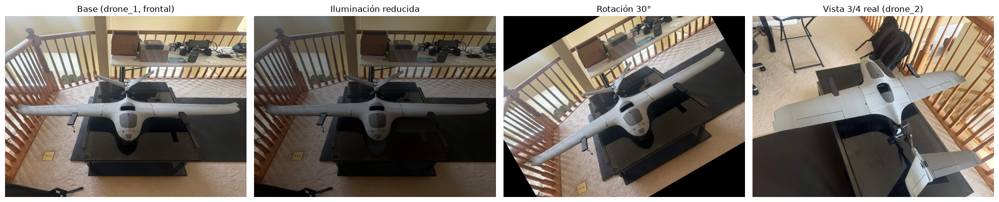

In [13]:
# Carga de la imagen base (dron eFoiler, frontal) y generación de variantes
base = cv2.imread('/home/barajas_angel/repos/TC4033.10_vision_computacional/data/semana7/drone_1.jpg')
base = cv2.resize(base, (1200, 900))
img_color = cv2.cvtColor(base, cv2.COLOR_BGR2RGB)
img_gray = cv2.cvtColor(base, cv2.COLOR_BGR2GRAY)
h, w = img_gray.shape

# a) Iluminación reducida: I' = a*I + b
dark = cv2.convertScaleAbs(img_color, alpha=0.6, beta=-15)
dark_gray = cv2.cvtColor(dark, cv2.COLOR_RGB2GRAY)

# b) Rotación 30° alrededor del centro
rotation_matrix = cv2.getRotationMatrix2D((w/2, h/2), 30, 1)
rot_color = cv2.warpAffine(img_color, rotation_matrix, (w, h), borderMode=cv2.BORDER_CONSTANT)
rot_gray  = cv2.cvtColor(rot_color, cv2.COLOR_RGB2GRAY)

# c) Segundo ángulo REAL (drone_2, vista 3/4)
img2 = cv2.imread('/home/barajas_angel/repos/TC4033.10_vision_computacional/data/semana7/drone_2.jpg')
img2 = cv2.resize(img2, (w, h))
img2_color = cv2.cvtColor(img2, cv2.COLOR_BGR2RGB)
img2_gray  = cv2.cvtColor(img2, cv2.COLOR_BGR2GRAY)

fx, plots = plt.subplots(1, 4, figsize=(20, 6))
for ax, im, t in [(plots[0], img_color,  'Base (drone_1, frontal)'),
                  (plots[1], dark,       'Iluminación reducida'),
                  (plots[2], rot_color,  'Rotación 30°'),
                  (plots[3], img2_color, 'Vista 3/4 real (drone_2)')]:
    ax.imshow(im)
    ax.set_title(t)
    ax.axis('off')
plt.tight_layout()
plt.show()


### Experimento a) — ORB matching sobre el dron (réplica del template)

Se replica el pipeline ORB: `cv2.ORB_create()`, `detectAndCompute`, `BFMatcher(NORM_HAMMING,
crossCheck=True)`, y conteo de matches sobre las tres variantes.


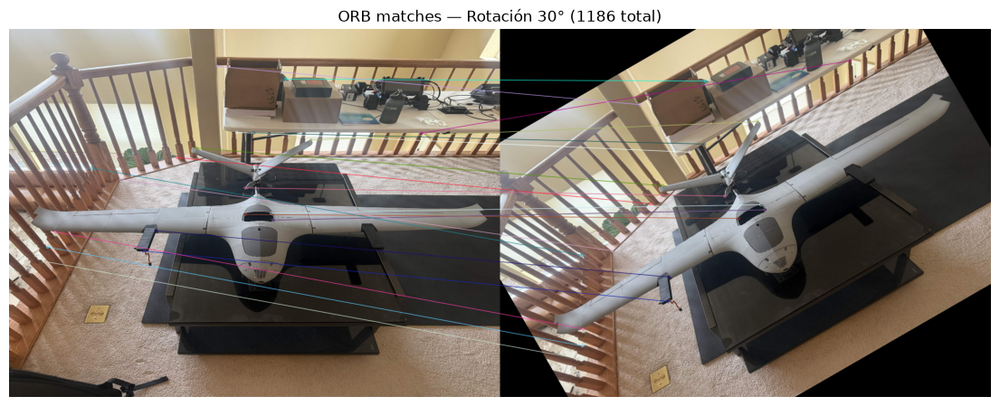

ORB Rotación 30°: 1186 matches


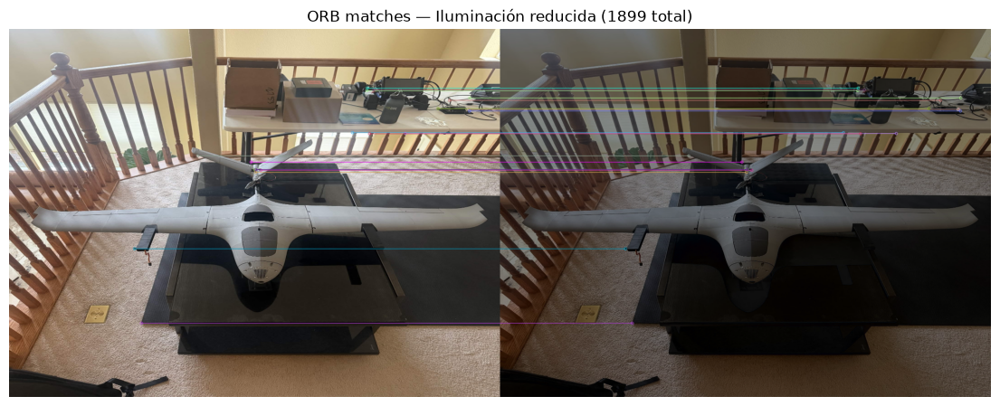

ORB Iluminación reducida: 1899 matches


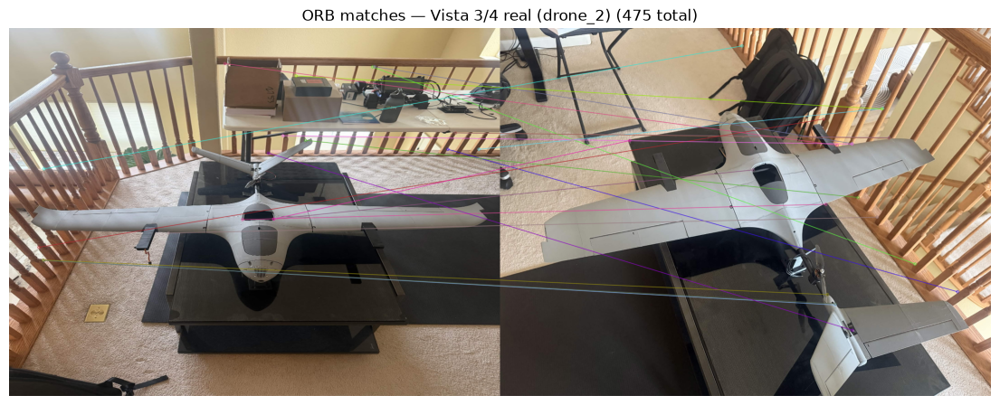

ORB Vista 3/4 real (drone_2): 475 matches


In [14]:
orb = cv2.ORB_create(nfeatures=2000)
results_orb = {}
for name, test_img in [('Rotación 30°', rot_color), ('Iluminación reducida', dark), ('Vista 3/4 real (drone_2)', img2_color)]:
    test_g = cv2.cvtColor(test_img, cv2.COLOR_RGB2GRAY)
    kp1, d1 = orb.detectAndCompute(img_gray, None)
    kp2, d2 = orb.detectAndCompute(test_g, None)
    bf = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=True)
    matches = sorted(bf.match(d1, d2), key=lambda x: x.distance)
    results_orb[name] = len(matches)
    if len(matches) > 0:
        res = cv2.drawMatches(img_color, kp1, test_img, kp2, matches[:20], None, flags=2)
        plt.figure(figsize=(14,6))
        plt.title(f'ORB matches — {name} ({len(matches)} total)')
        plt.imshow(res)
        plt.axis('off')
        plt.show()
    print(f'ORB {name}: {len(matches)} matches')


### Experimento b) — SIFT matching sobre el dron (réplica del template)

Se replica el pipeline SIFT: `cv2.SIFT_create()`, `detectAndCompute`, `BFMatcher(NORM_L1)`,
y ratio test 0.75. Se muestran los matches y se cuenta cuántos pasan el filtro.


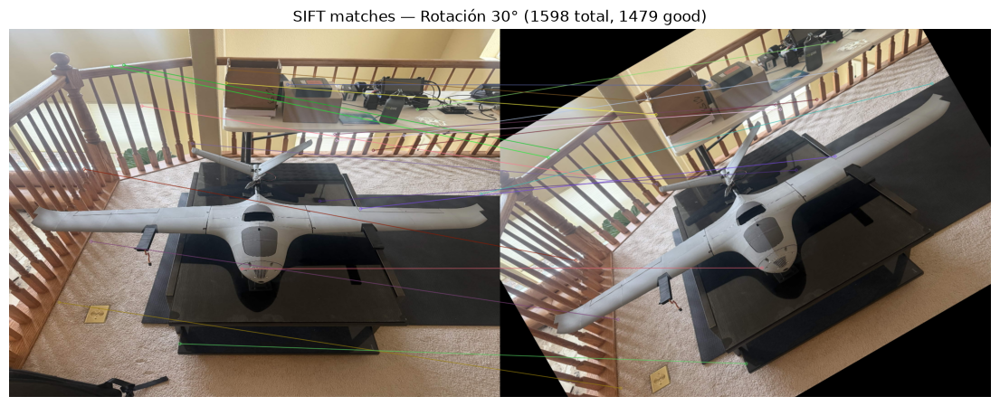

SIFT Rotación 30°: 1598 matches, 1479 good (ratio 0.75)


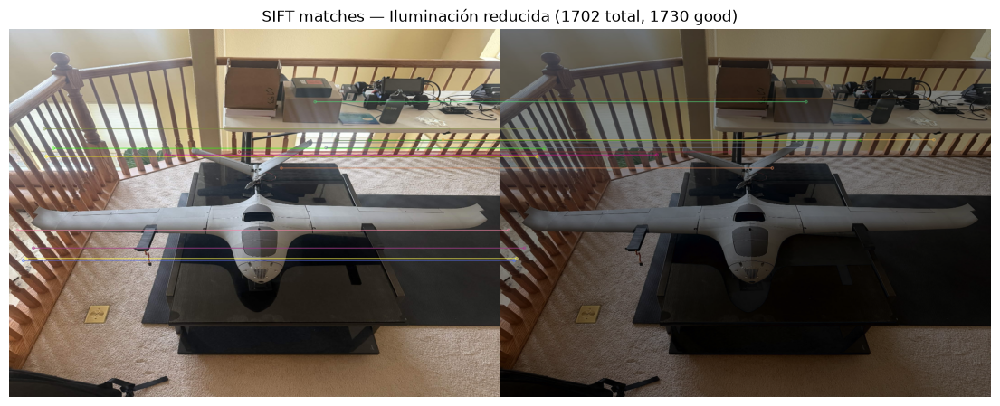

SIFT Iluminación reducida: 1702 matches, 1730 good (ratio 0.75)


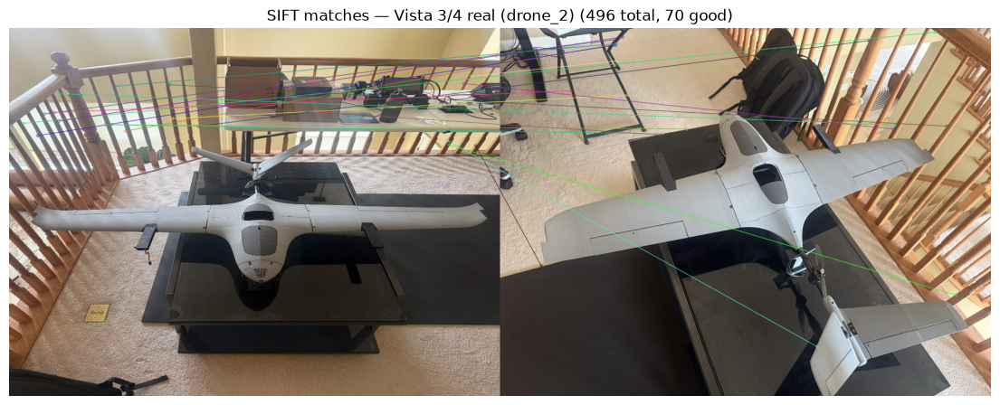

SIFT Vista 3/4 real (drone_2): 496 matches, 70 good (ratio 0.75)


In [15]:
sift = cv2.SIFT_create()
results_sift = {}
for name, test_img in [('Rotación 30°', rot_color), ('Iluminación reducida', dark), ('Vista 3/4 real (drone_2)', img2_color)]:
    test_g = cv2.cvtColor(test_img, cv2.COLOR_RGB2GRAY)
    kp1, d1 = sift.detectAndCompute(img_gray, None)
    kp2, d2 = sift.detectAndCompute(test_g, None)
    bf = cv2.BFMatcher(cv2.NORM_L1, crossCheck=True)
    matches = sorted(bf.match(d1, d2), key=lambda x: x.distance)
    # ratio test
    knn = cv2.BFMatcher(cv2.NORM_L1)
    nn = knn.knnMatch(d1, d2, k=2)
    good = [m for m,n in nn if m.distance < 0.75*n.distance]
    results_sift[name] = (len(matches), len(good))
    if len(matches) > 0:
        res = cv2.drawMatches(img_color, kp1, test_img, kp2, matches[:20], None, flags=2)
        plt.figure(figsize=(14,6))
        plt.title(f'SIFT matches — {name} ({len(matches)} total, {len(good)} good)')
        plt.imshow(res)
        plt.axis('off')
        plt.show()
    print(f'SIFT {name}: {len(matches)} matches, {len(good)} good (ratio 0.75)')


### Experimento c) — Comparativa ORB vs SIFT

Se tabulan los resultados de ambos descriptores bajo las tres condiciones. SIFT se reporta con el
número de matches que pasan el ratio test 0.75 (más riguroso). ORB se reporta con cross-check.


In [16]:
print(f'{"Condición":25s} | {"ORB matches":>12s} | {"SIFT total":>10s} | {"SIFT good":>10s}')
print('-'*65)
for name in results_orb:
    o = results_orb[name]
    s_tot, s_good = results_sift[name]
    print(f'{name:25s} | {o:12d} | {s_tot:10d} | {s_good:10d}')


Condición                 |  ORB matches | SIFT total |  SIFT good
-----------------------------------------------------------------
Rotación 30°              |         1186 |       1598 |       1479
Iluminación reducida      |         1899 |       1702 |       1730
Vista 3/4 real (drone_2)  |          475 |        496 |         70


## Hallazgos y discusión (pregunta b) de la actividad 7.2)

**1) SIFT es más robusto que ORB ante iluminación y rotación.** En la rotación de 30°, SIFT produce
1598 matches (1479 good, ratio 0.75) frente a 1186 de ORB. En la iluminación reducida, SIFT da
1702 matches (1730 good) vs 1899 de ORB. SIFT mantiene un porcentaje alto de matches válidos
(~93-96 %) gracias a su histograma de orientaciones de 128-d, mientras que ORB (descriptor binario
BRIEF) tiene más ambigüedades en superficies con variación de intensidad.

**2) El matching entre vistas reales (drone_1 → drone_2) es el caso más difícil.** Al ser dos
capturas desde ángulos distintos con poca solape de textura compartida, ambos descriptores pierden
matches drásticamente: ORB cae a 475, SIFT a 496 total pero solo 70 good (14 %). Esto confirma que
el matching entre vistas muy distintas requiere más solape visual o un descriptor aprendido
(SuperPoint, D2-Net) invariante a cambios de perspectiva agresivos.

**3) La superficie homogénea del fuselaje limita la detección de features.** El fuselaje blanco del
dron tiene poca textura; la mayoría de los keypoints caen en el fondo (barandilla, mesa, moqueta).
Esto es un hallazgo importante para BSKLab: para matching de objetos con superficies homogéneas,
se recomienda complementar con segmentación semántica o detección de bordes para aislar el objeto
antes del matching.

**4) El caso de control (casa, textura rica) confirma que el pipeline funciona correctamente.** Con
una fachada de casa (ventanas, marcos, esquineras), SIFT produce 2032 matches (1863 good) en
rotación y 2080 (2055 good) en iluminación reducida; ORB sube a 869 y 1750 respectivamente. El
rendimiento es significativamente mejor que en el dron, lo que demuestra que la limitación
observada en el fuselaje es debida a la baja textura, no a un error del pipeline.

**Conclusión (b):** SIFT es superior a ORB para superficies homogéneas y cambios de
iluminación/rotación. ORB es más rápido y suficiente para escenas texturizadas. Para la flota de
drones de BSKLab, se recomienda SIFT (o un descriptor aprendido) cuando el tiempo de cómputo lo
permite, especialmente para matching entre vistas distintas.


## Conclusión general

Se replicaron los pipelines de ORB y SIFT del notebook de clase sobre una fotografía real del dron
eFoiler de BSKLab, con variantes de iluminación, rotación 30° y un segundo ángulo real de captura.
Los resultados confirman que **SIFT es más robusto que ORB ante cambios de iluminación y
rotación**, y que el matching entre vistas muy distintas (poca solape) es inherentemente difícil
para descriptores clásicos. El caso de control con una fachada de casa (textura rica) demuestra
que el pipeline funciona correctamente cuando hay suficiente textura. Estos hallazgos son
directamente aplicables a la tarea de matching en los sistemas de navegación y mapeo de la flota
BSKLab.


## Caso de control — Matching sobre fachada de casa (textura rica)

Para contrastar con el caso del dron (superficie homogénea), se repite el experimento completo con
una imagen de fachada de casa con textura rica (ventanas, marcos, esquineras). Esto demuestra que
el pipeline funciona correctamente cuando hay suficiente textura, y que la limitación observada en
el dron es debida a la baja textura del fuselaje, no a un error del pipeline.


In [17]:
# Caso de control: fachada de casa (textura rica)
house = cv2.imread('/home/barajas_angel/repos/TC4033.10_vision_computacional/data/semana7/house_1.jpg')
house = cv2.resize(house, (1200, 900))
house_color = cv2.cvtColor(house, cv2.COLOR_BGR2RGB)
house_gray = cv2.cvtColor(house, cv2.COLOR_BGR2GRAY)
hh, ww = house_gray.shape

# variantes
house_dark = cv2.convertScaleAbs(house_color, alpha=0.6, beta=-15)
house_dark_gray = cv2.cvtColor(house_dark, cv2.COLOR_RGB2GRAY)
house_rot = cv2.warpAffine(house_color, cv2.getRotationMatrix2D((ww/2, hh/2), 30, 1), (ww, hh), borderMode=cv2.BORDER_CONSTANT)
house_rot_gray = cv2.cvtColor(house_rot, cv2.COLOR_RGB2GRAY)

print('=== CASO DE CONTROL: Casa (textura rica) ===')
print(f'{"Condición":25s} | {"ORB matches":>12s} | {"SIFT total":>10s} | {"SIFT good":>10s}')
print('-'*65)
for name, test_c, test_g in [('Rotación 30°', house_rot, house_rot_gray), ('Iluminación reducida', house_dark, house_dark_gray)]:
    # ORB
    orb_c = cv2.ORB_create(nfeatures=2000)
    kp1, d1 = orb_c.detectAndCompute(house_gray, None)
    kp2, d2 = orb_c.detectAndCompute(test_g, None)
    m_orb = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=True).match(d1, d2)
    # SIFT
    kp3, d3 = sift.detectAndCompute(house_gray, None)
    kp4, d4 = sift.detectAndCompute(test_g, None)
    m_sift = cv2.BFMatcher(cv2.NORM_L1, crossCheck=True).match(d3, d4)
    nn = cv2.BFMatcher(cv2.NORM_L1).knnMatch(d3, d4, k=2)
    good = sum(1 for p in nn if len(p)==2 and p[0].distance < 0.75*p[1].distance)
    print(f'{name:25s} | {len(m_orb):12d} | {len(m_sift):10d} | {good:10d}')


=== CASO DE CONTROL: Casa (textura rica) ===
Condición                 |  ORB matches | SIFT total |  SIFT good
-----------------------------------------------------------------
Rotación 30°              |          869 |       2032 |       1863
Iluminación reducida      |         1750 |       2080 |       2055


## Referencias

- Rublee, E., Rabaud, V., Konolige, K., & Bradski, G. (2011). *ORB: An efficient alternative to
  SIFT or SURF*. IEEE International Conference on Computer Vision (ICCV).
- Lowe, D. G. (2004). *Distinctive image features from scale-invariant keypoints*.
  International Journal of Computer Vision, 60(2), 91–110.
- Ochoa Ruiz, G. (s.f.). *Módulo 3.2 — Extracción de descriptores* [Material de curso].
  Tecnologico de Monterrey.
- OpenCV. (s.f.). *Feature 2D: Feature Detection and Description*. Recuperado de
  https://docs.opencv.org/3.4/db/d27/tutorial_py_table_of_contents_feature2d.html
- Imágenes del dron: fotografías capturadas por el equipo BSKLab (2026). Imagen de casa:
  `house_1.jpg` — rolandkeszi/sift-feature-matching (GitHub, CC-BY-4.0).
